# CBMViz Core Pipeline Tutorial

This tutorial explains how to use the CBMViz core pipeline to visualize a genome-scale model. All functions use the H. pylori model *iIT341* as example which can be found at http://bigg.ucsd.edu/models/iIT341. 

In [ ]:
import os
import cbmviz

In order to use CBMViz to create a layout you first have to set up an initial graph. The function **createInitialGraph** takes care of that and returns the new graph object as well as a dictionary containing all of its properties.


In [ ]:
graph, graph_props = cbmviz.createInitialGraph("iIT341")

To layout your model you need to call the function **layoutModel** which requires

- *global_ops* (the CBMViz configuration dictionary that can be accessed by entering 'cbmviz.cfg_default'),
- *sbml* (a string containing the path to your SBML model file) and
- *graph* and *graph_props* (the two initial objects created above)

and returns

- *cmod* (a CBMPY model object),
- *fba_results* (a dictionary containing flux values for each reaction which have been calculated by doing an FBA),
- *graph_registry* (a dictionary containing all generated graphs - your output!),
- *cDir* (the current directory) and
- *output_path* (the output_path)

In [ ]:
# get configuration dictionary with default values
global_ops = cbmviz.cfg_default

# get path of test model
sbml = os.path.join("TestModels", "iIT341.xml")

cmod, fba_results, graph_registry, cDir, output_path = cbmviz.layoutModel(global_ops, sbml, graph, graph_props)

Once the layout has been created the resulting graph objects are saved in the dictionary *graph_registry* which can serve as input for the coloring function **colorGraphs**. Besides *graph_registry* this function also requires

- *global_ops*,
- *fba_results* (or any other dictionary that maps reaction ids to some floating point values),
- *output_path* and
- *model_id* (a string containing the id of the model or any other name)

In this example the coloring function takes in the FBA results to color each reaction edge depending on the flux value but there are also other coloring modes possible such as coloring gaps when comparing two models or coloring individual pathways.


In [ ]:
cbmviz.colorGraphs(global_ops, fba_results, graph_registry, output_path, "iIT341")

Eventually the finished layout can be exported by the function **exportGraph**, which requires

- *output_path*,
- *graph_registry*,
- *global_ops*,
- *cDir* and
- *model_id*

All output will be exported to one output folder in the current working directory. Possible output formats are

- SVG (.svg)
- GML (.gml)
- JSON (.json)
- Tulip graph (.tlp)

In [ ]:
cbmviz.exportGraph(output_path, graph_registry, global_ops, cDir, "iIT341")

Example: 
Visualization of the TCA cycle (from the output SVG file).

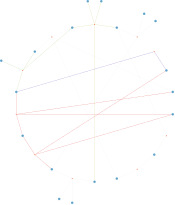

In [10]:
from IPython.display import SVG
SVG(filename='iIT341_Output\\TCAcycle.svg')
